In [3]:
import decoupler as dc
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

c:\Users\asd123cheese\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
macro = sc.read_h5ad('../data_processed/filtered_macro_pb.h5ad')
endo = sc.read_h5ad('../data_processed/filtered_endo_pb.h5ad')

In [5]:
gobp = dc.pp.read_gmt('../data_interim/gmt/m5.go.bp.v2026.1.Mm.symbols.gmt')
hallmark = dc.pp.read_gmt('../data_interim/gmt/mh.all.v2026.1.Mm.symbols.gmt')
reactome = dc.pp.read_gmt('../data_interim/gmt/m2.cp.reactome.v2026.1.Mm.symbols.gmt')
gocc = dc.pp.read_gmt('../data_interim/gmt/m5.go.cc.v2026.1.Mm.symbols.gmt')
gomf = dc.pp.read_gmt('../data_interim/gmt/m5.go.mf.v2026.1.Mm.symbols.gmt')

In [6]:
deg_endo_heart = pd.read_excel('../data_processed/DEG_endo_heart.xlsx', index_col=0)
deg_macro_heart = pd.read_excel('../data_processed/DEG_macro_heart.xlsx', index_col=0)
deg_endo_kidney = pd.read_excel('../data_processed/DEG_endo_kidney.xlsx', index_col=0)
deg_macro_kidney = pd.read_excel('../data_processed/DEG_macro_kidney.xlsx', index_col=0)
deg_endo_liver = pd.read_excel('../data_processed/DEG_endo_liver.xlsx', index_col=0)
deg_macro_liver = pd.read_excel('../data_processed/DEG_macro_liver.xlsx', index_col=0)
deg_endo_lung = pd.read_excel('../data_processed/DEG_endo_lung.xlsx', index_col=0)
deg_macro_lung = pd.read_excel('../data_processed/DEG_macro_lung.xlsx', index_col=0)

In [7]:
def gene_set_filter(gset, min_size, max_size, name):
    gset_size = gset.groupby("source").size()
    keep = gset_size.between(min_size, max_size)
    print(f"{name}：筛选前 {len(gset_size)}，筛选后 {keep.sum()}")
    return gset.loc[gset["source"].isin(gset_size.index[keep])]

reactome, gobp, hallmark, gocc, gomf = [
    gene_set_filter(gset, 15, 200, name)
    for name, gset in (
        ("reactome", reactome),
        ("gobp", gobp),
        ("hallmark", hallmark),
        ("gocc", gocc),
        ("gomf", gomf),
    )
]

reactome：筛选前 1333，筛选后 792
gobp：筛选前 7781，筛选后 3866
hallmark：筛选前 50，筛选后 50
gocc：筛选前 1067，筛选后 485
gomf：筛选前 1899，筛选后 806


In [8]:
net = pd.concat(
    [
        hallmark.assign(collection="Hallmark"),
        reactome.assign(collection="Reactome"),
        gobp.assign(collection="GO:BP"),
        gocc.assign(collection="GO:CC"),
        gomf.assign(collection="GO:MF"),
    ],
    ignore_index=True,
)

In [9]:
def prepare_data(cell, tissue):
    deg = (
        pd.read_excel(f"../data_processed/DEG_{cell}_{tissue}.xlsx", index_col=0).set_index("variable").dropna(subset=["adj_p_value"])
    )
    return ad.AnnData(
        deg[["adj_p_value"]].lt(0.05).astype(float).T.rename(index={"adj_p_value": "old vs young"})
    )
(data_macro_heart, data_macro_kidney, data_macro_liver, data_macro_lung,data_endo_heart, data_endo_kidney, data_endo_liver, data_endo_lung) =[
    prepare_data(cell, tissue)
    for cell in ("macro", "endo")
    for tissue in ("heart", "kidney", "liver", "lung")
]

In [10]:
def run_enrichment(data, net, tissue, tmin):
    dc.mt.ora(
        data=data,
        net=net,
        tmin=tmin,
        empty=False,
        n_up=data.n_vars - int(data.X.sum()),
        n_bg=data.n_vars,
    )
    return pd.DataFrame({
        "bh_fdr": data.obsm["padj_ora"].iloc[0],
        "ora_score": data.obsm["score_ora"].iloc[0],
    })

In [11]:
ora_results = {
    (cell, tissue): run_enrichment(data, net, tissue, tmin=3)
    for cell, tissue, data in (
        ("macro", "Heart_and_Aorta", data_macro_heart),
        ("macro", "Kidney", data_macro_kidney),
        ("macro", "Liver", data_macro_liver),
        ("macro", "Lung", data_macro_lung),
        ("endo", "Heart_and_Aorta", data_endo_heart),
        ("endo", "Kidney", data_endo_kidney),
        ("endo", "Liver", data_endo_liver),
        ("endo", "Lung", data_endo_lung),
    )
}

In [12]:
ora_matrices = {}

for cell in ("endo", "macro"):
    results = pd.concat({
        tissue: result
        for (cell_type, tissue), result in ora_results.items()
        if cell_type == cell
    }, axis=1)

    bh_fdr = results.xs("bh_fdr", axis=1, level=1).T
    ora_score = results.xs("ora_score", axis=1, level=1).T

    ora_matrices[cell] = {
        "values": np.stack([bh_fdr.to_numpy(), ora_score.to_numpy()], axis=-1),
        "tissues": ora_score.index,
        "pathways": ora_score.columns,
        "metrics": ("bh_fdr", "ora_score"),
    }

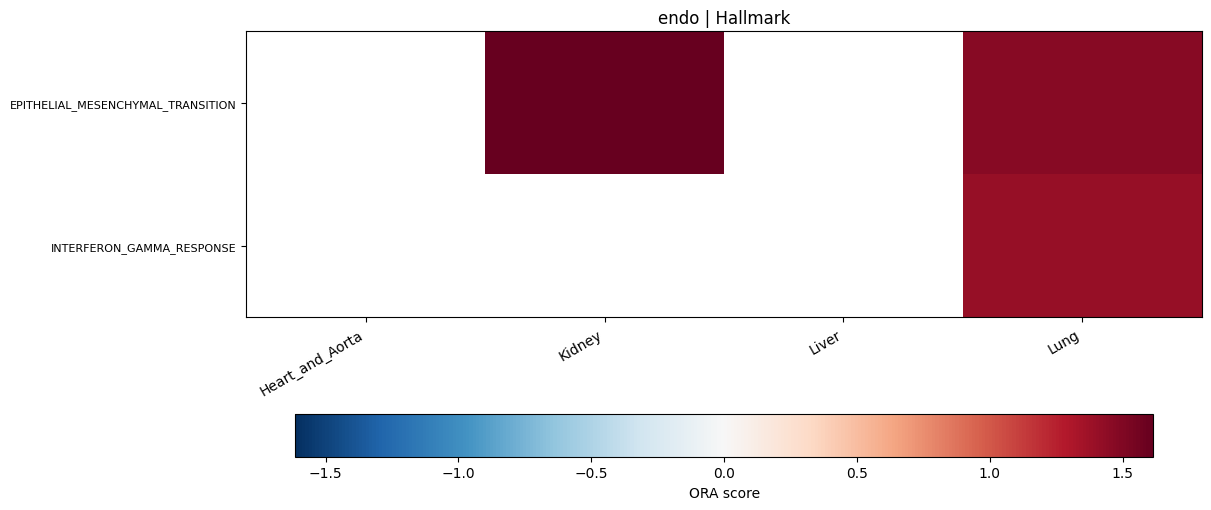

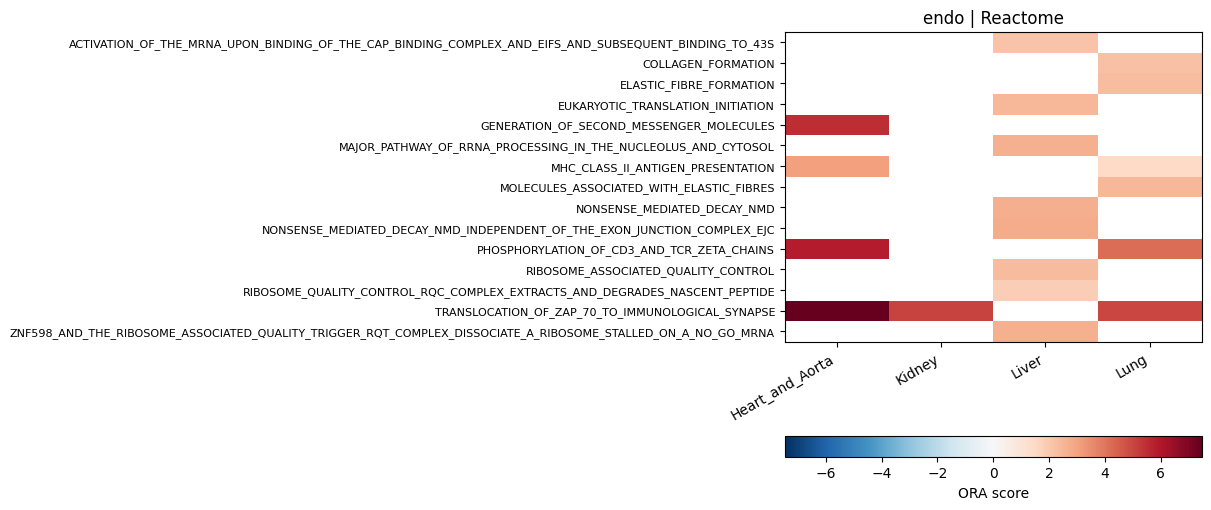

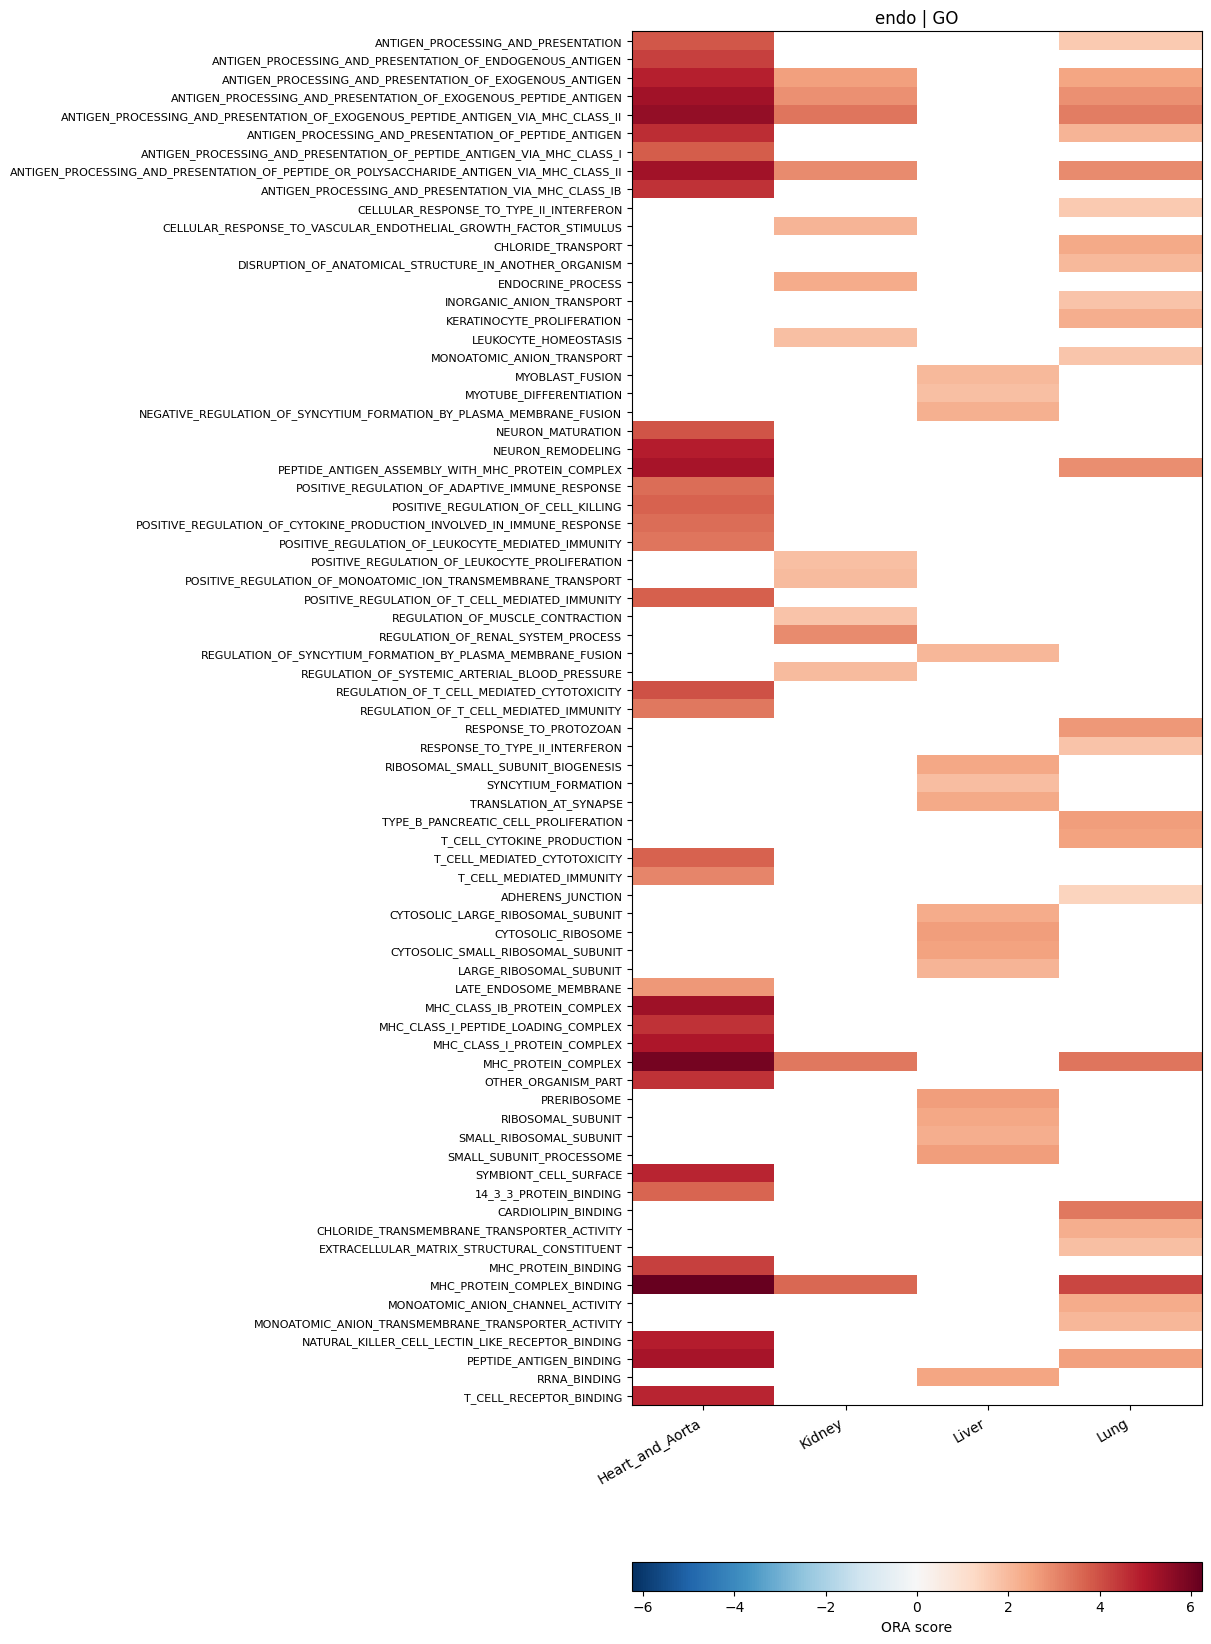

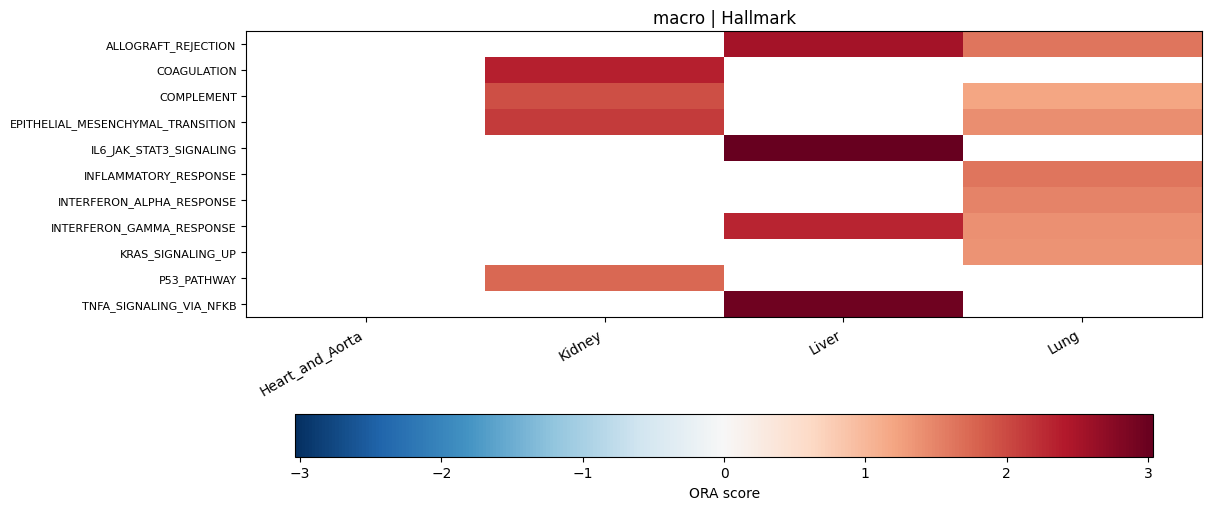

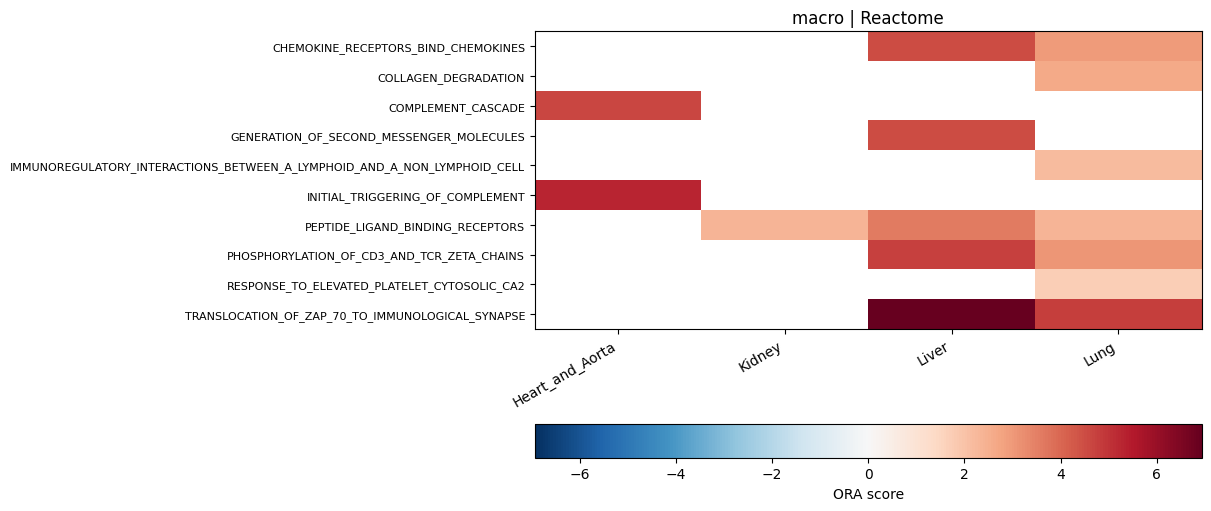

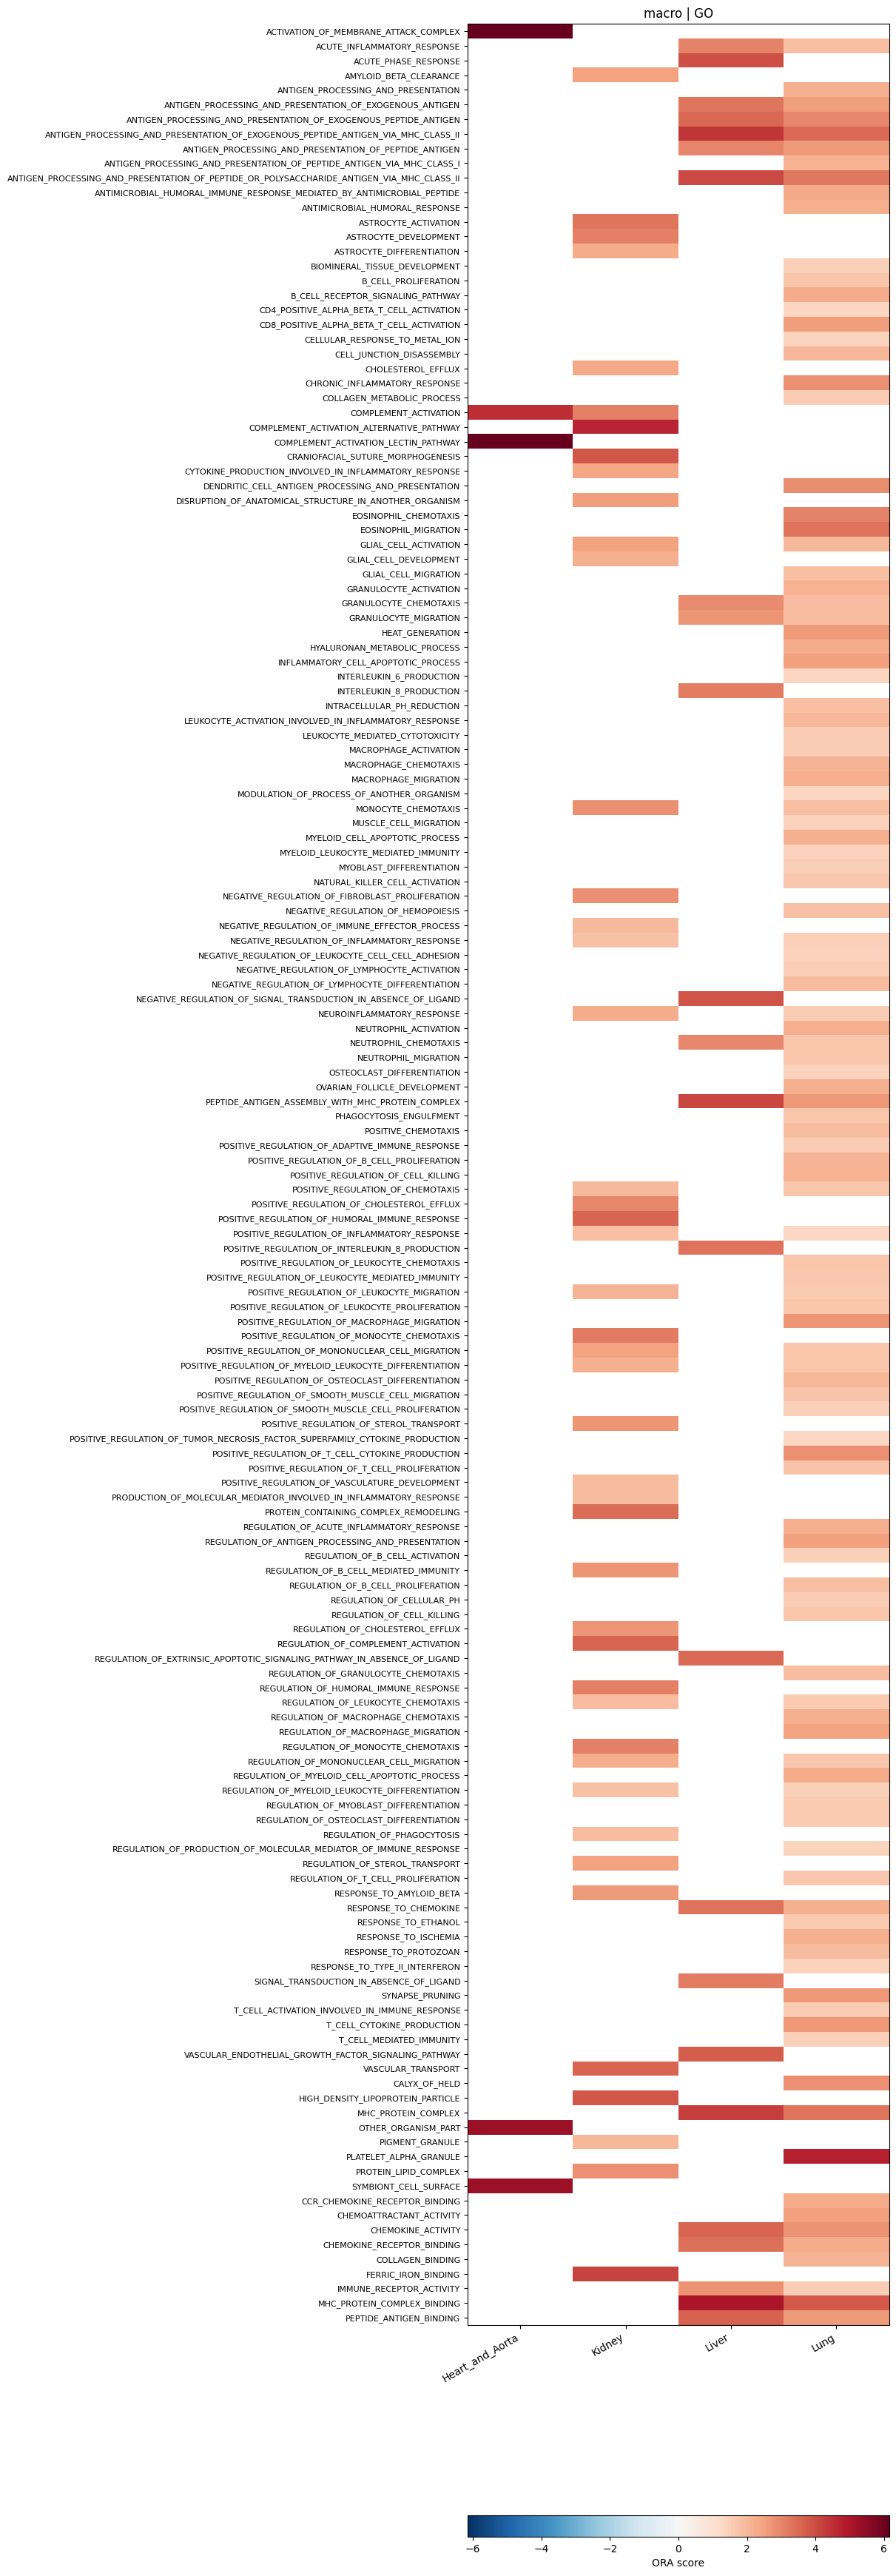

In [13]:
import matplotlib.pyplot as plt

for cell, matrix in ora_matrices.items():
    bh_fdr = matrix["values"][:, :, 0]
    ora_score = matrix["values"][:, :, 1]

    scores = pd.DataFrame(
        np.where((bh_fdr < 0.05) & (ora_score > 0), ora_score, np.nan),
        index=matrix["tissues"],
        columns=matrix["pathways"],
    ).dropna(axis=1, how="all")

    for name, collections in (
        ("Hallmark", ["Hallmark"]),
        ("Reactome", ["Reactome"]),
        ("GO", ["GO:BP", "GO:CC", "GO:MF"]),
    ):
        paths = scores.columns.intersection(
            net.loc[net["collection"].isin(collections), "source"],
            sort=False,
        )
        if paths.empty:
            continue

        labels = paths.str.replace(
            r"^(?:(?:GO:?BP|GO:?CC|GO:?MF|Hallmark|Reactome)[_ |:-]+)+",
            "",
            case=False,
            regex=True,
        )
        plot = scores.loc[:, paths].T
        vmax = plot.max().max()

        fig, ax = plt.subplots(
            figsize=(12, max(5, 0.22 * len(paths))),
            layout="constrained",
        )
        image = ax.imshow(
            plot.to_numpy(),
            aspect="auto",
            interpolation="nearest",
            cmap=plt.get_cmap("RdBu_r").with_extremes(bad="white"),
            vmin=-vmax,
            vmax=vmax,
        )
        ax.set_title(f"{cell} | {name}")
        ax.set_xticks(range(plot.shape[1]), plot.columns, rotation=30, ha="right")
        ax.set_yticks(range(len(labels)), labels, fontsize=8)

        fig.colorbar(image, ax=ax, orientation="horizontal", label="ORA score")
        plt.show()

In [20]:
false_positive_paths = {
    ("endo", "Heart_and_Aorta"): {
        "GOBP_NEURON_MATURATION",
        "GOBP_NEURON_REMODELING",
        "GOCC_OTHER_ORGANISM_PART",
    },
    ("endo", "Liver"): {
        "GOBP_MYOBLAST_FUSION",
        "GOBP_TRANSLATION_AT_SYNAPSE",
        "GOBP_NEGATIVE_REGULATION_OF_SYNCYTIUM_FORMATION_BY_PLASMA_MEMBRANE_FUSION",
    },
    ("endo", "Lung"): {
        "GOBP_KERATINOCYTE_PROLIFERATION",
        "GOBP_TYPE_B_PANCREATIC_CELL_PROLIFERATION",
    },
    ("macro", "Heart_and_Aorta"): {
        "GOCC_OTHER_ORGANISM_PART",
    },
    ("macro", "Kidney"): {
        "GOBP_ASTROCYTE_ACTIVATION",
        "GOBP_ASTROCYTE_DEVELOPMENT",
        "GOBP_ASTROCYTE_DIFFERENTIATION",
        "GOBP_GLIAL_CELL_DEVELOPMENT",
        "GOBP_GLIAL_CELL_ACTIVATION",
        "GOBP_CRANIOFACIAL_SUTURE_MORPHOGENESIS",
        "GOBP_NEUROINFLAMMATORY_RESPONSE",
    },
    ("macro", "Lung"): {
        "GOBP_GLIAL_CELL_MIGRATION",
        "GOBP_GLIAL_CELL_ACTIVATION",
        "GOBP_OSTEOCLAST_DIFFERENTIATION",
        "GOBP_REGULATION_OF_OSTEOCLAST_DIFFERENTIATION",
        "GOBP_POSITIVE_REGULATION_OF_OSTEOCLAST_DIFFERENTIATION",
        "GOBP_OVARIAN_FOLLICLE_DEVELOPMENT",
        "GOCC_CALYX_OF_HELD",
        "GOCC_PLATELET_ALPHA_GRANULE",
        "GOBP_MYOBLAST_DIFFERENTIATION",
        "GOBP_REGULATION_OF_MYOBLAST_DIFFERENTIATION",
        "GOBP_POSITIVE_REGULATION_OF_SMOOTH_MUSCLE_CELL_MIGRATION",
        "GOBP_HEAT_GENERATION",
    },
}

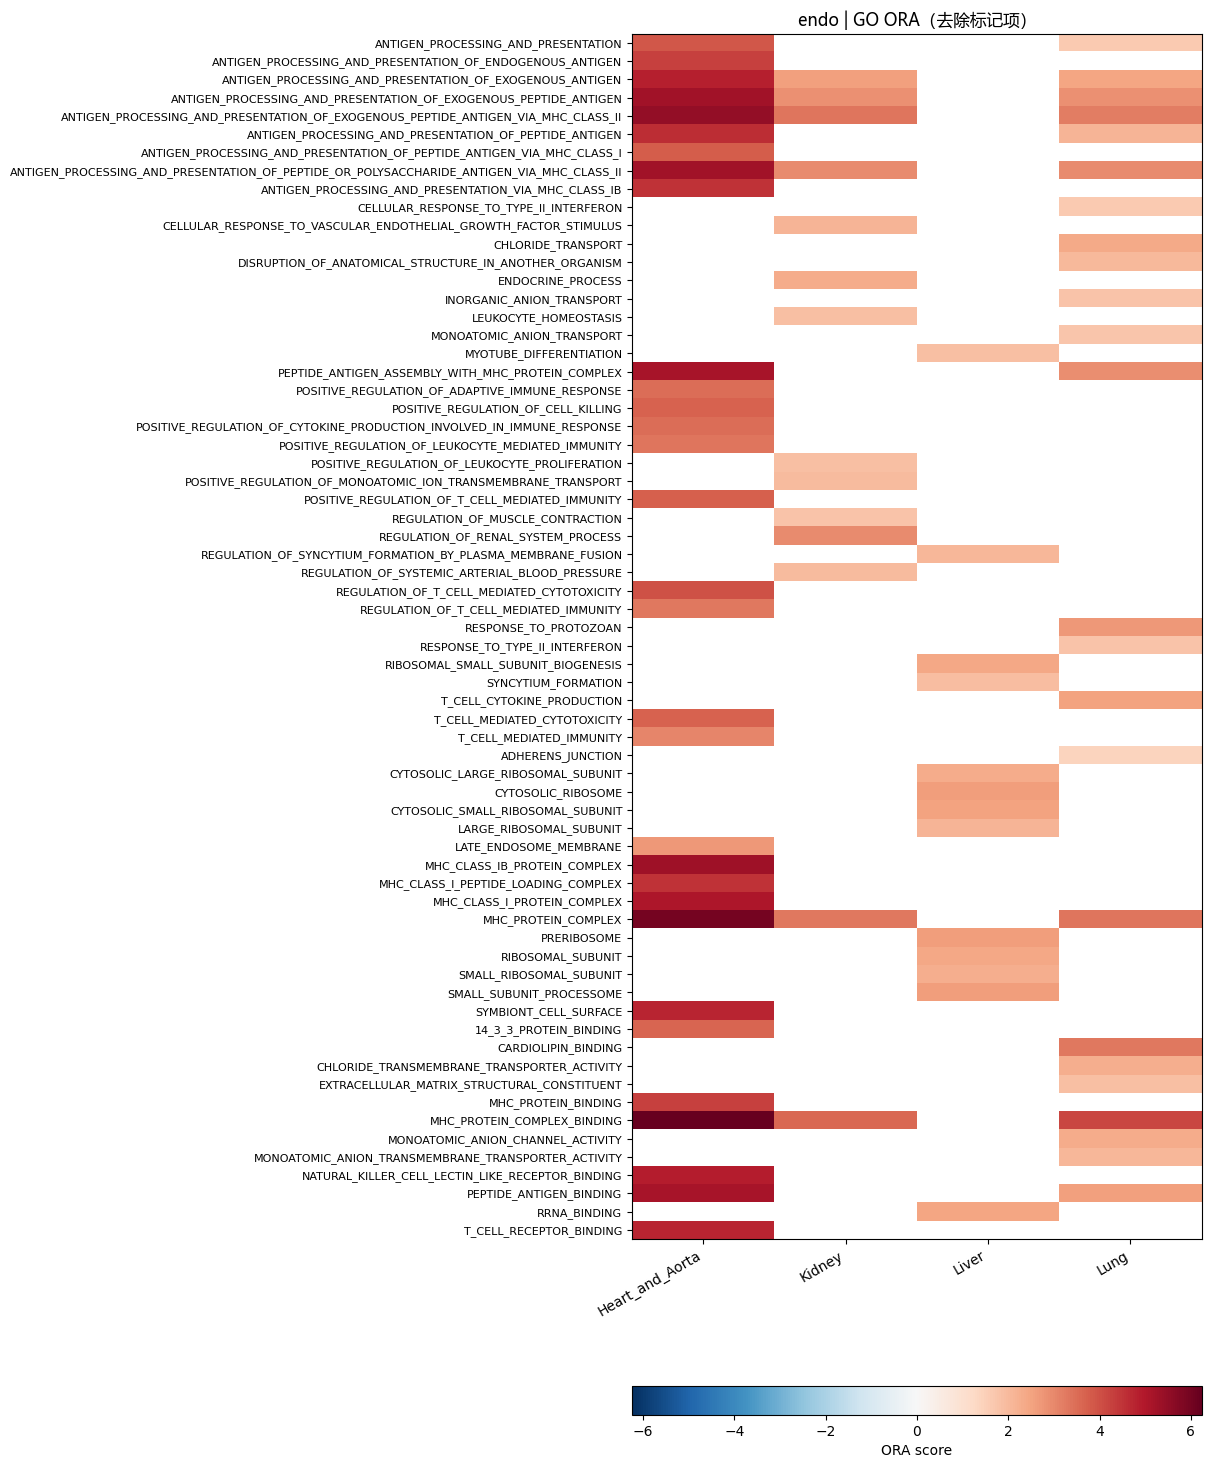

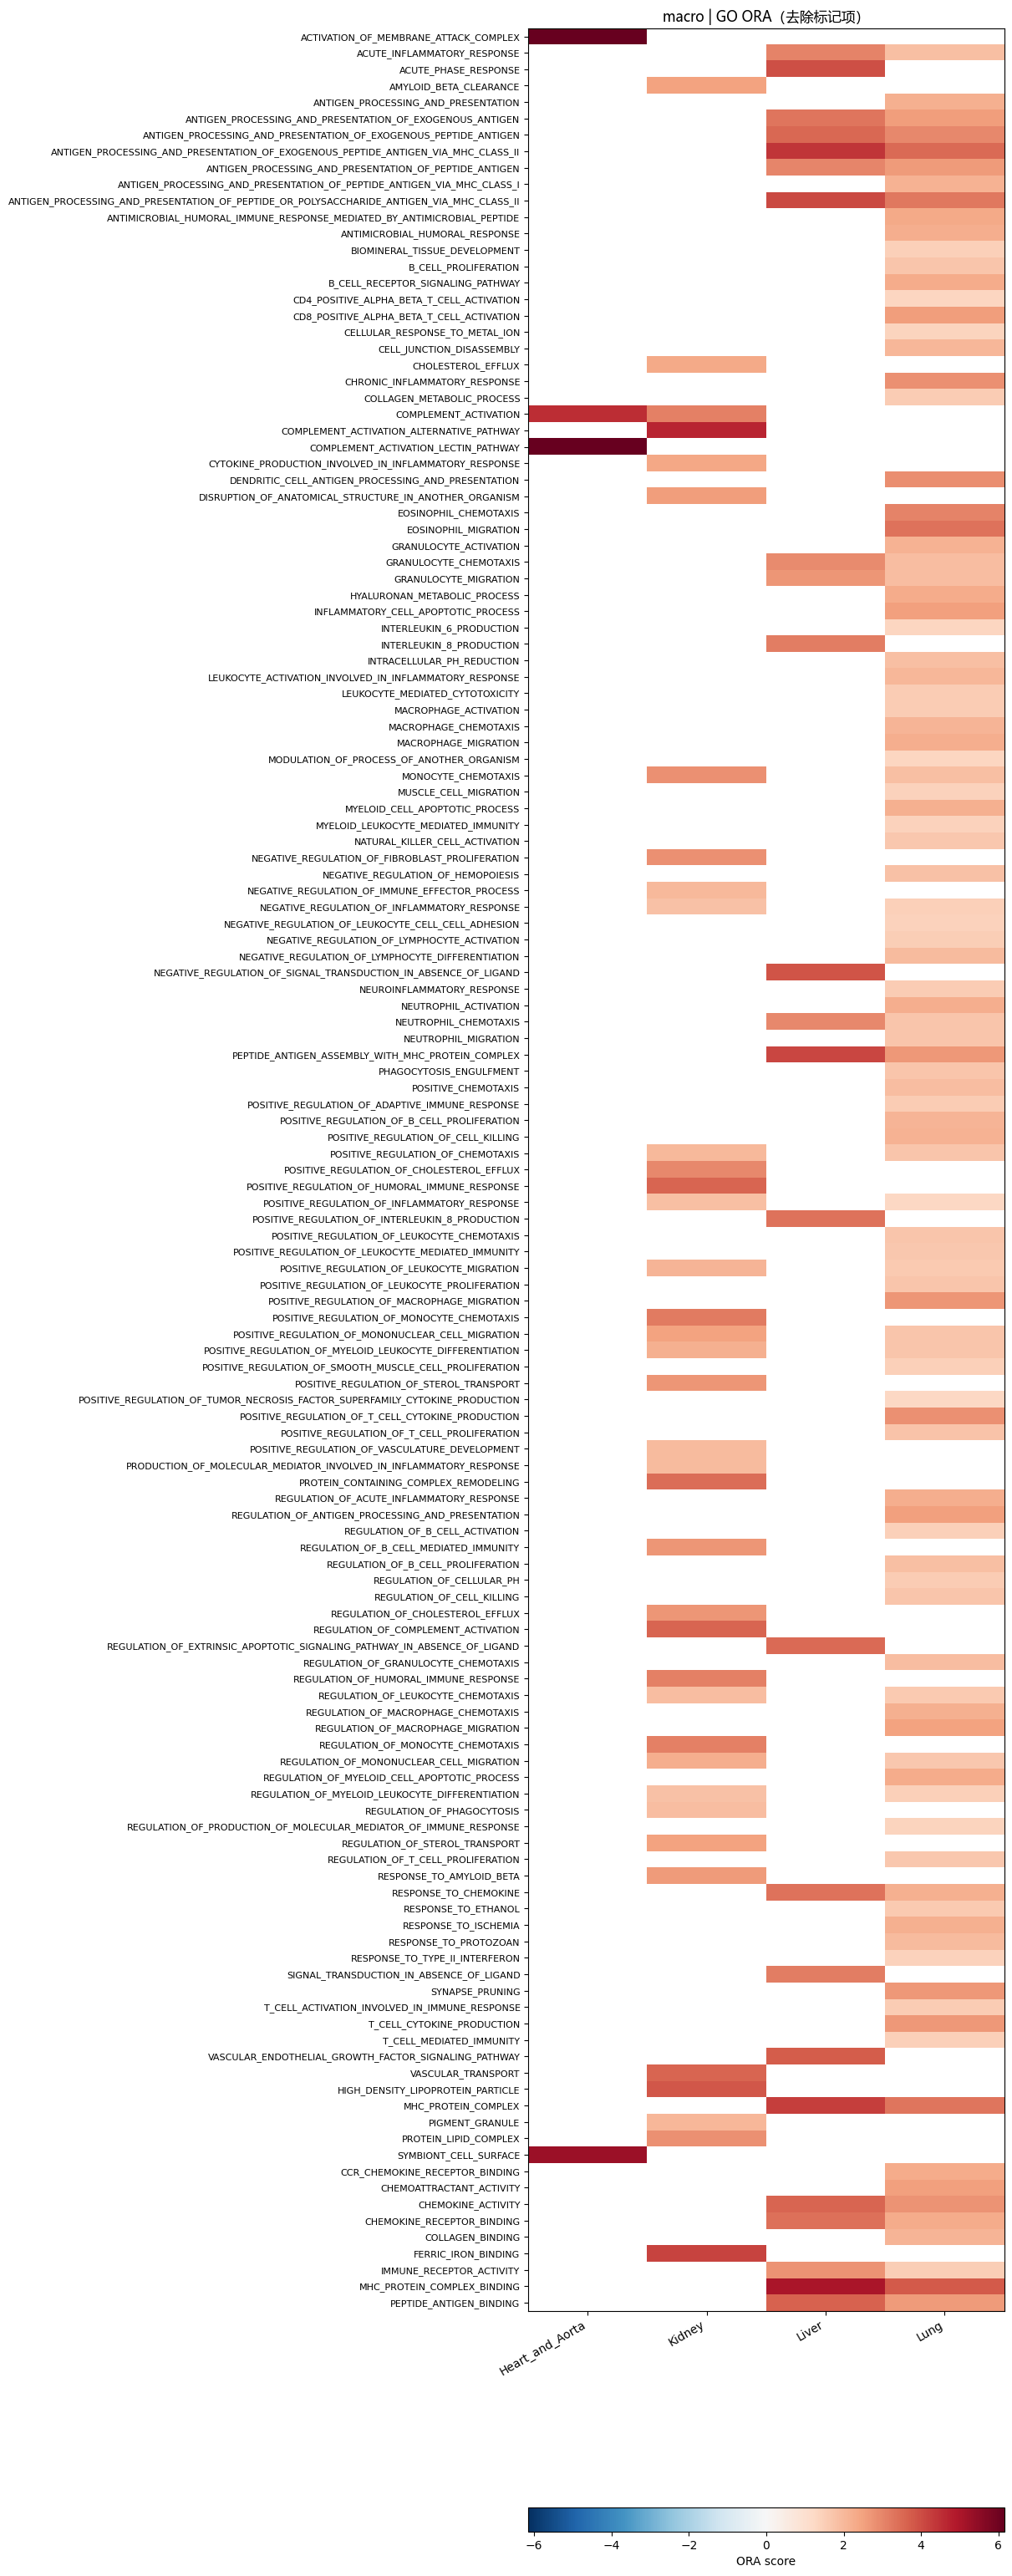

In [21]:
go_paths = net.loc[
    net["collection"].isin(["GO:BP", "GO:CC", "GO:MF"]), "source"
]

for cell, matrix in ora_matrices.items():
    bh_fdr = matrix["values"][:, :, 0]
    ora_score = matrix["values"][:, :, 1]

    scores = pd.DataFrame(
        np.where((bh_fdr < 0.05) & (ora_score > 0), ora_score, np.nan),
        index=matrix["tissues"],
        columns=matrix["pathways"],
    )
    scores = scores.loc[:, scores.columns.intersection(go_paths, sort=False)]
    vmax = scores.max().max()

    for tissue in scores.index:
        flagged = false_positive_paths.get((cell, tissue), ())
        scores.loc[tissue, scores.columns.isin(flagged)] = np.nan

    plot = scores.dropna(axis=1, how="all").T
    if plot.empty:
        continue

    labels = plot.index.str.replace(r"^GO(?:BP|CC|MF)_", "", regex=True)
    fig, ax = plt.subplots(
        figsize=(12, max(5, 0.22 * len(plot))),
        layout="constrained",
    )
    image = ax.imshow(
        plot.to_numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap=plt.get_cmap("RdBu_r").with_extremes(bad="white"),
        vmin=-vmax,
        vmax=vmax,
    )
    ax.set_title(f"{cell} | GO ORA（去除标记项）", fontfamily="Microsoft YaHei")
    ax.set_xticks(range(plot.shape[1]), plot.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(plot)), labels, fontsize=8)

    fig.colorbar(image, ax=ax, orientation="horizontal", label="ORA score")
    plt.show()